# INT315: Cluster Computing - Academic Task 2 Project
## Project Title: Predicting Employee Salaries Using Apache Spark MLlib & Graph Analytics

**Course Code:** INT315  
**Course Name:** Cluster Computing  
**Evaluation Rubric:** CO4, CO5, CO6 (Bloom's Level L3, L4 - 30 Marks)  

---
### Project Objective & Scope
This project implements an end-to-end distributed big-data architecture using **Apache Spark**, **Spark MLlib**, and **Graph Analytics** to model and predict employee salaries. Key requirements covered:
1. **System Architecture Design:** Cluster computing topology using Spark Core, Spark SQL DataFrames, and MLlib Pipeline.
2. **Distributed Data Ingestion & Preprocessing:** Distributed CSV reading, schema inference, data validation, and memory caching.
3. **Graph Analytics:** Enterprise hierarchy modeling, managerial span-of-control, and centrality vs. compensation correlation.
4. **Distributed Feature Engineering & Regression:** Multi-stage Spark MLlib Pipeline using `StringIndexer`, `OneHotEncoder`, and `VectorAssembler`, followed by `LinearRegression`.
5. **Model Evaluation & Visualizations:** Evaluation with Mean Squared Error (MSE), RMSE, MAE, R², and plotting **Years of Experience vs. Predicted Salary**.

### Step 1: Environment Setup & SparkSession Initialization
Configure Java 17 and initialize local distributed SparkSession.

In [1]:
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')

# Set Java 17 environment path
jdk_path = os.path.abspath(r'.\jdk17_extracted\jdk-17.0.14+7')
if os.path.exists(jdk_path):
    os.environ['JAVA_HOME'] = jdk_path
    os.environ['PATH'] = os.path.join(jdk_path, 'bin') + ';' + os.environ.get('PATH', '')

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import networkx as nx

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# Initialize Spark Session
spark = SparkSession.builder \
    .appName('EmployeeSalaryPrediction_INT315') \
    .master('local[*]') \
    .config('spark.driver.memory', '2g') \
    .getOrCreate()

spark.sparkContext.setLogLevel('ERROR')
print(f'Apache Spark initialized successfully! Version: {spark.version}')
print(f'Master Node: {spark.sparkContext.master} | Total Parallel Cores: {spark.sparkContext.defaultParallelism}')

Apache Spark initialized successfully! Version: 4.3.0
Master Node: local[*] | Total Parallel Cores: 16


### Step 2: Distributed Data Ingestion & Preprocessing
Load the employee dataset into a distributed PySpark DataFrame, verify schema, and inspect summary statistics.

In [2]:
data_path = 'employee_salaries.csv'
df = spark.read.csv(data_path, header=True, inferSchema=True)

print(f'Total Distributed Records: {df.count()}')
print(f'Number of Partitions: {df.rdd.getNumPartitions()}')

print('\n--- Dataset Schema ---')
df.printSchema()

print('\n--- First 5 Records ---')
df.show(5, truncate=False)

# Check for missing/null values across columns
null_counts = {c: df.filter(F.col(c).isNull()).count() for c in df.columns}
print(f'Null Check: {null_counts}')

# Statistical distribution
df.select('years_experience', 'salary').describe().show()

Total Distributed Records: 2500
Number of Partitions: 1

--- Dataset Schema ---
root
 |-- emp_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- job_title: string (nullable = true)
 |-- department: string (nullable = true)
 |-- education: string (nullable = true)
 |-- years_experience: double (nullable = true)
 |-- project_id: string (nullable = true)
 |-- manager_id: string (nullable = true)
 |-- salary: double (nullable = true)


--- First 5 Records ---


+-------+-------------+--------------------+----------+---------+----------------+----------+----------+---------+
|emp_id |name         |job_title           |department|education|years_experience|project_id|manager_id|salary   |
+-------+-------------+--------------------+----------+---------+----------------+----------+----------+---------+
|EMP0001|Kenneth Davis|Engineering Director|Management|Master   |14.3            |PROJ_02   |EMP0000   |262161.58|
|EMP0002|Michael Baker|Engineering Director|Management|Master   |22.1            |PROJ_03   |EMP0000   |318617.87|
|EMP0003|Donna Ramirez|Engineering Director|Management|Master   |14.3            |PROJ_04   |EMP0000   |262913.04|
|EMP0004|Mary Scott   |Engineering Director|Management|PhD      |16.2            |PROJ_05   |EMP0000   |292472.46|
|EMP0005|Joseph Lewis |Engineering Director|Management|Master   |20.5            |PROJ_06   |EMP0000   |305614.18|
+-------+-------------+--------------------+----------+---------+---------------

Null Check: {'emp_id': 0, 'name': 0, 'job_title': 0, 'department': 0, 'education': 0, 'years_experience': 0, 'project_id': 0, 'manager_id': 0, 'salary': 0}


+-------+-----------------+-----------------+
|summary| years_experience|           salary|
+-------+-----------------+-----------------+
|  count|             2500|             2500|
|   mean|4.845039999999982|90847.97610799978|
| stddev|2.919119713605618|37280.51999900417|
|    min|              0.5|         39752.23|
|    max|             24.7|        350465.51|
+-------+-----------------+-----------------+



### Step 3: Graph Analytics (Enterprise Hierarchy & Collaboration Modeling)
We model organizational relationships (employee-manager reporting lines and project collaboration networks) to analyze topological centrality and its relationship with compensation.

Correlation between Managerial Centrality (Reports Managed) and Salary: 0.6621


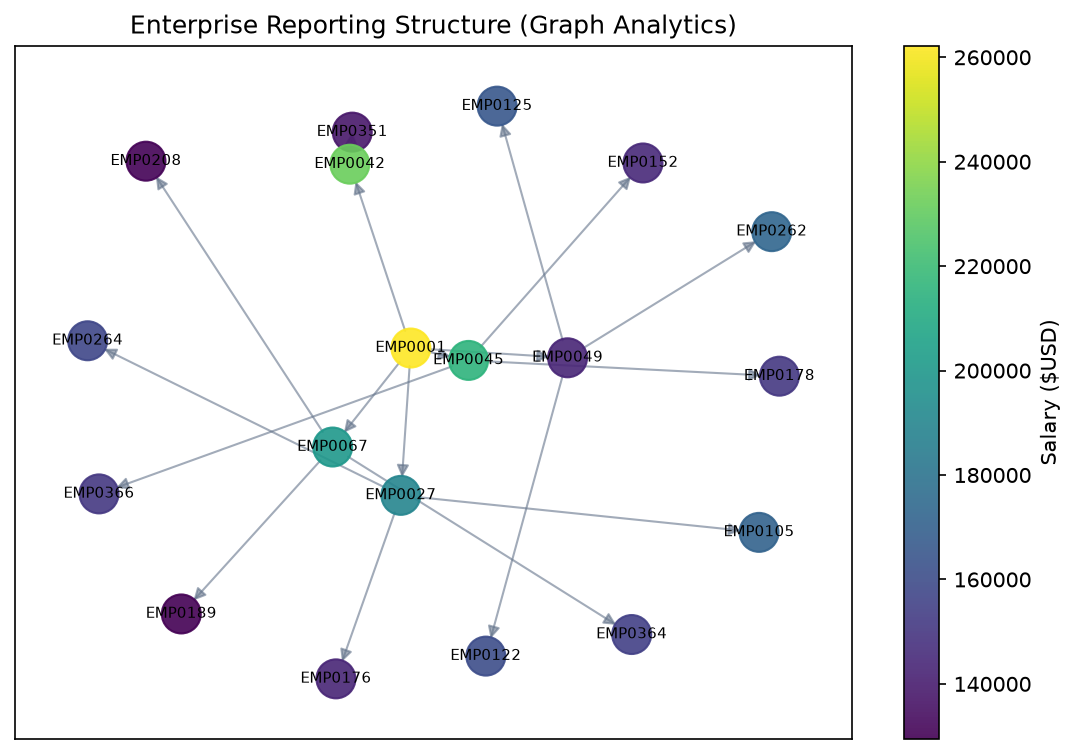

In [3]:
pdf = df.toPandas()

# Construct Directed Organizational Graph
G_org = nx.DiGraph()
for _, row in pdf.iterrows():
    G_org.add_node(row['emp_id'], title=row['job_title'], salary=row['salary'], exp=row['years_experience'])
    if row['manager_id'] and row['manager_id'] != 'EMP0000':
        G_org.add_edge(row['manager_id'], row['emp_id'])

out_degrees = dict(G_org.out_degree())
pdf['direct_reports'] = pdf['emp_id'].map(out_degrees).fillna(0)

corr = pdf['direct_reports'].corr(pdf['salary'])
print(f'Correlation between Managerial Centrality (Reports Managed) and Salary: {corr:.4f}')

# Visualize Subgraph
sample_nodes = ['EMP0001']
for n1 in list(G_org.successors('EMP0001'))[:6]:
    sample_nodes.append(n1)
    sample_nodes.extend(list(G_org.successors(n1))[:3])

subgraph = G_org.subgraph(sample_nodes)
pos = nx.spring_layout(subgraph, seed=42)
node_salaries = [subgraph.nodes[n].get('salary', 60000) for n in subgraph.nodes()]

plt.figure(figsize=(9, 6), dpi=150)
sc = nx.draw_networkx_nodes(subgraph, pos, node_size=350, node_color=node_salaries, cmap='viridis', alpha=0.9)
nx.draw_networkx_edges(subgraph, pos, arrows=True, arrowsize=12, edge_color='#64748b', alpha=0.6)
nx.draw_networkx_labels(subgraph, pos, font_size=7)
plt.colorbar(sc, label='Salary ($USD)')
plt.title('Enterprise Reporting Structure (Graph Analytics)')
plt.show()

### Step 4: Machine Learning Pipeline (Spark MLlib)
Encode categorical attributes (`job_title`, `department`, `education`) using `StringIndexer` and `OneHotEncoder`, assemble features with `VectorAssembler`, and train `LinearRegression`.

In [4]:
# Index categorical columns
indexer_title = StringIndexer(inputCol='job_title', outputCol='title_idx', handleInvalid='keep')
indexer_dept = StringIndexer(inputCol='department', outputCol='dept_idx', handleInvalid='keep')
indexer_edu = StringIndexer(inputCol='education', outputCol='edu_idx', handleInvalid='keep')

# One-Hot Encode indexed columns
encoder = OneHotEncoder(
    inputCols=['title_idx', 'dept_idx', 'edu_idx'],
    outputCols=['title_vec', 'dept_vec', 'edu_vec'],
    dropLast=False
)

# Combine into feature vector
assembler = VectorAssembler(
    inputCols=['years_experience', 'title_vec', 'dept_vec', 'edu_vec'],
    outputCol='features'
)

# Define Linear Regression
lr = LinearRegression(featuresCol='features', labelCol='salary', maxIter=100, regParam=0.01)

# Build Spark Pipeline
pipeline = Pipeline(stages=[indexer_title, indexer_dept, indexer_edu, encoder, assembler, lr])

# 80/20 Train/Test Split
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)
print(f'Training Set: {train_df.count()} | Testing Set: {test_df.count()}')

# Train Pipeline
pipeline_model = pipeline.fit(train_df)
print('Spark MLlib Pipeline Training Complete!')

Training Set: 2051 | Testing Set: 449


Spark MLlib Pipeline Training Complete!


### Step 5: Model Evaluation (MSE, RMSE, MAE, R²)
Evaluate the model on unseen test data using `RegressionEvaluator`.

In [5]:
predictions = pipeline_model.transform(test_df).cache()

eval_mse = RegressionEvaluator(labelCol='salary', predictionCol='prediction', metricName='mse')
eval_rmse = RegressionEvaluator(labelCol='salary', predictionCol='prediction', metricName='rmse')
eval_mae = RegressionEvaluator(labelCol='salary', predictionCol='prediction', metricName='mae')
eval_r2 = RegressionEvaluator(labelCol='salary', predictionCol='prediction', metricName='r2')

mse = eval_mse.evaluate(predictions)
rmse = eval_rmse.evaluate(predictions)
mae = eval_mae.evaluate(predictions)
r2 = eval_r2.evaluate(predictions)

print('=' * 50)
print('           MODEL PERFORMANCE EVALUATION')
print('=' * 50)
print(f'Mean Squared Error (MSE)       : {mse:,.2f}')
print(f'Root Mean Squared Error (RMSE) : ${rmse:,.2f}')
print(f'Mean Absolute Error (MAE)      : ${mae:,.2f}')
print(f'Coefficient of Determination R²: {r2:.4f} ({r2*100:.2f}%)')
print('=' * 50)

           MODEL PERFORMANCE EVALUATION
Mean Squared Error (MSE)       : 15,694,916.14
Root Mean Squared Error (RMSE) : $3,961.68
Mean Absolute Error (MAE)      : $3,149.60
Coefficient of Determination R²: 0.9889 (98.89%)


### Step 6: Plotting Experience vs. Predicted Salary
Visualize the relationship between employee experience and both actual and predicted salaries.

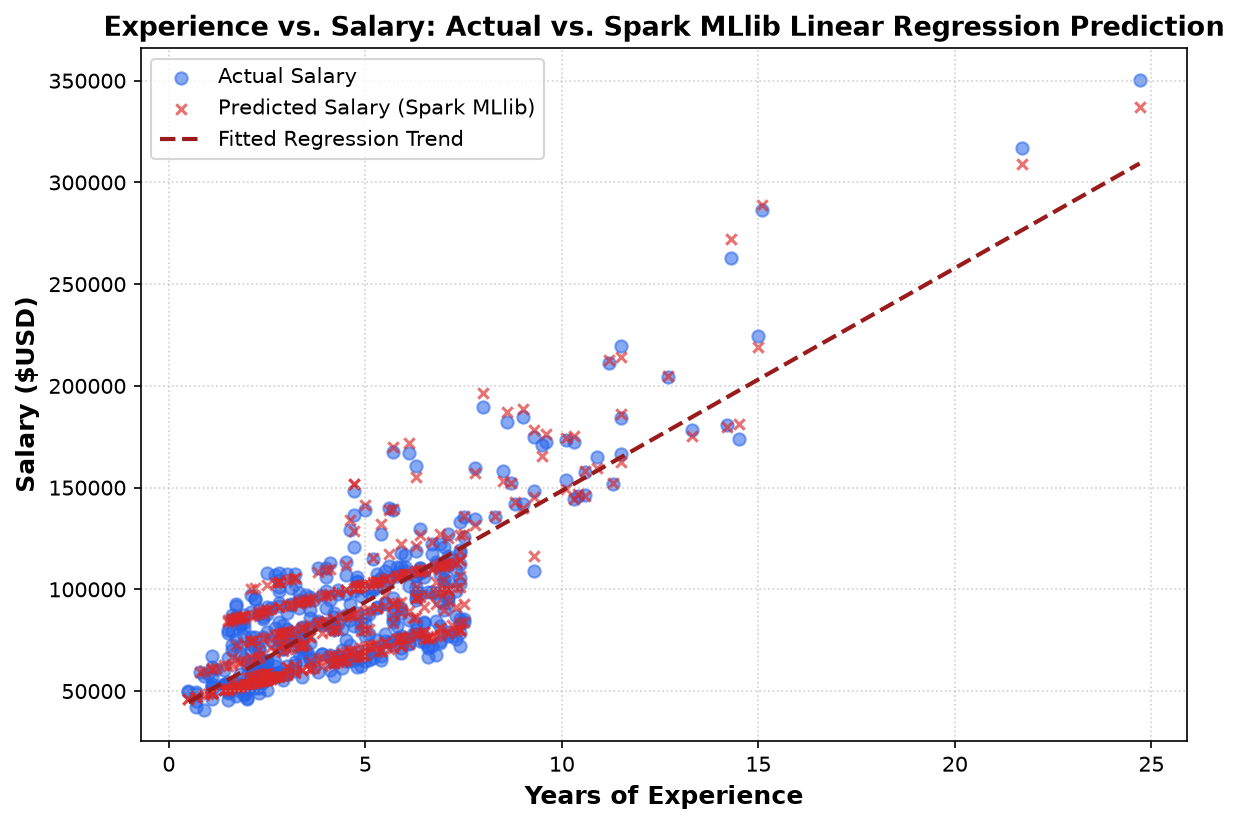

In [6]:
pred_pdf = predictions.select('years_experience', 'salary', 'prediction', 'job_title').toPandas()

plt.figure(figsize=(9, 6), dpi=150)
plt.scatter(pred_pdf['years_experience'], pred_pdf['salary'], color='#2563eb', alpha=0.55, label='Actual Salary', s=35)
plt.scatter(pred_pdf['years_experience'], pred_pdf['prediction'], color='#dc2626', alpha=0.65, label='Predicted Salary (Spark MLlib)', s=25, marker='x')

# Fit trend line
z = np.polyfit(pred_pdf['years_experience'], pred_pdf['prediction'], 1)
p = np.poly1d(z)
exp_range = np.linspace(pred_pdf['years_experience'].min(), pred_pdf['years_experience'].max(), 100)
plt.plot(exp_range, p(exp_range), color='#991b1b', linestyle='--', linewidth=2, label='Fitted Regression Trend')

plt.xlabel('Years of Experience', fontsize=12, fontweight='bold')
plt.ylabel('Salary ($USD)', fontsize=12, fontweight='bold')
plt.title('Experience vs. Salary: Actual vs. Spark MLlib Linear Regression Prediction', fontsize=13, fontweight='bold')
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Step 7: Parity Plot & Residual Error Distribution
Examine prediction deviations and confirm Gaussian normal distribution of errors.

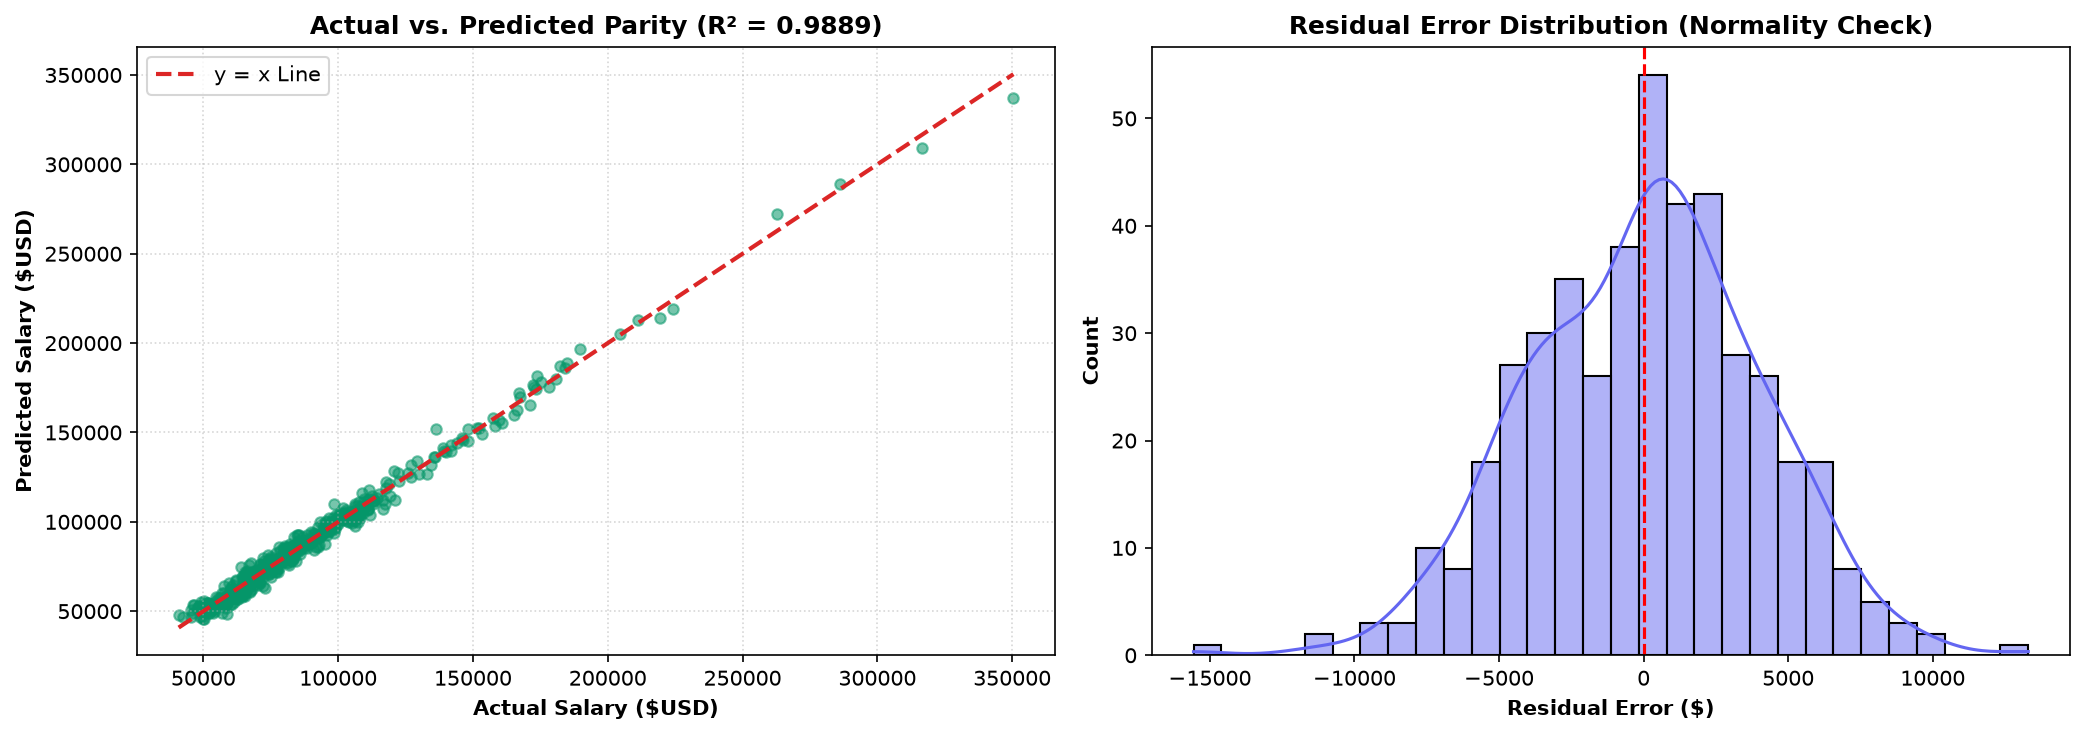

In [7]:
pred_pdf['residual'] = pred_pdf['salary'] - pred_pdf['prediction']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Parity plot
ax1.scatter(pred_pdf['salary'], pred_pdf['prediction'], color='#059669', alpha=0.55, s=25)
min_val = min(pred_pdf['salary'].min(), pred_pdf['prediction'].min())
max_val = max(pred_pdf['salary'].max(), pred_pdf['prediction'].max())
ax1.plot([min_val, max_val], [min_val, max_val], color='#dc2626', linestyle='--', linewidth=2, label='y = x Line')
ax1.set_xlabel('Actual Salary ($USD)', fontweight='bold')
ax1.set_ylabel('Predicted Salary ($USD)', fontweight='bold')
ax1.set_title(f'Actual vs. Predicted Parity (R² = {r2:.4f})', fontweight='bold')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.5)

# Residual distribution
sns.histplot(pred_pdf['residual'], kde=True, color='#6366f1', ax=ax2, bins=30)
ax2.axvline(0, color='red', linestyle='--')
ax2.set_xlabel('Residual Error ($)', fontweight='bold')
ax2.set_ylabel('Count', fontweight='bold')
ax2.set_title('Residual Error Distribution (Normality Check)', fontweight='bold')

plt.tight_layout()
plt.show()

### Step 8: Clean Up Resources
Stop SparkSession.

In [8]:
spark.stop()
print('SparkSession stopped successfully!')

SparkSession stopped successfully!
